# Community Detection — CDlib 

In [2]:
# If CDlib is not installed, run:
%pip install cdlib igraph leidenalg networkx pandas numpy matplotlib scikit-learn

import os
import random
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from cdlib import algorithms, evaluation, NodeClustering

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

CSV_PATH = "/mnt/data/bluesky_large_edges_unweighted_10000 (1).csv"
METADATA_PATH = "/mnt/data/ticker_metadata.csv"

OUTPUT_DIR = "analysis_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("CDlib imported successfully.")

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/3.2 MB ? eta -:--:--
   ---------------- ----------------------- 1.3/3.2 MB 5.5 MB/s eta 0:00:01
   -------------------------------- ------- 2.6/3.2 MB 5.9 MB/s eta 0:00:01
   ---------------------------------------- 3.2/3.2 MB 5.2 MB/s  0:00:00
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ------------------------------- -------- 1.6/2.0 MB 6.7 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 5.2 MB/s  0:00:00
   ---------------------------------------- 0.0/16.4 MB ? eta -:--:--
   ---- ----------------------------------- 1.8/16.4 MB 9.3 MB/s eta 0:00:02
   --------

In [4]:
# Load edge list and ticker metadata
edges_df = pd.read_csv("bluesky_large_edges_unweighted_10000 (1).csv")
metadata = pd.read_csv("ticker_metadata.csv")

print("Edges shape:", edges_df.shape)
print("Metadata shape:", metadata.shape)
print("Edge columns:", list(edges_df.columns))
print("Metadata columns:", list(metadata.columns))

Edges shape: (462904, 3)
Metadata shape: (6243, 6)
Edge columns: ['source', 'target', 'weight']
Metadata columns: ['ticker', 'company', 'sector', 'industry', 'country', 'exchange']


In [5]:
# Verify that the edge weights do not add information
if "weight" in edges_df.columns:
    print(edges_df["weight"].describe())
    print("Unique weights:", edges_df["weight"].nunique())
    print("Unique values:", sorted(edges_df["weight"].dropna().unique())[:20])

# Identify edge endpoint columns
possible_pairs = [
    ("source", "target"),
    ("u", "v"),
    ("node1", "node2"),
    ("ticker1", "ticker2"),
]
pair_cols = next(
    ((a, b) for a, b in possible_pairs
     if a in edges_df.columns and b in edges_df.columns),
    None
)

if pair_cols is None:
    pair_cols = (edges_df.columns[0], edges_df.columns[1])

SOURCE_COL, TARGET_COL = pair_cols

G = nx.Graph()
G.add_edges_from(
    edges_df[[SOURCE_COL, TARGET_COL]].itertuples(index=False, name=None)
)

print("Endpoint columns:", SOURCE_COL, TARGET_COL)
print(f"Nodes: {G.number_of_nodes():,}")
print(f"Edges: {G.number_of_edges():,}")

count    462904.0
mean          1.0
std           0.0
min           1.0
25%           1.0
50%           1.0
75%           1.0
max           1.0
Name: weight, dtype: float64
Unique weights: 1
Unique values: [np.int64(1)]
Endpoint columns: source target
Nodes: 6,243
Edges: 462,904


In [6]:
# Identify ticker and sector columns in the metadata
ticker_candidates = ["ticker", "symbol", "Ticker", "Symbol"]
sector_candidates = ["sector", "Sector", "industry_sector"]

ticker_col = next((c for c in ticker_candidates if c in metadata.columns), None)
sector_col = next((c for c in sector_candidates if c in metadata.columns), None)

if ticker_col is None or sector_col is None:
    raise ValueError(
        f"Could not identify ticker/sector columns. "
        f"Available columns: {list(metadata.columns)}"
    )

metadata[ticker_col] = metadata[ticker_col].astype(str)
metadata[sector_col] = metadata[sector_col].fillna("Unknown").astype(str)

node_to_sector = dict(zip(metadata[ticker_col], metadata[sector_col]))

nx.set_node_attributes(G, node_to_sector, "sector")

known_nodes = [
    n for n in G.nodes()
    if node_to_sector.get(n, "Unknown") != "Unknown"
]

G_known = G.subgraph(known_nodes).copy()

print("Known-sector nodes:", G_known.number_of_nodes())
print("Known-sector edges:", G_known.number_of_edges())
print("Unknown-sector nodes:", G.number_of_nodes() - G_known.number_of_nodes())

Known-sector nodes: 5091
Known-sector edges: 431862
Unknown-sector nodes: 1152


## Sector diagnostics

These measures establish how much the official sector taxonomy is already reflected in the network before community detection.

In [7]:
same_sector_edges = 0
known_known_edges = 0

for u, v in G.edges():
    su = node_to_sector.get(u, "Unknown")
    sv = node_to_sector.get(v, "Unknown")
    if su != "Unknown" and sv != "Unknown":
        known_known_edges += 1
        if su == sv:
            same_sector_edges += 1

sector_counts = pd.Series(
    [node_to_sector[n] for n in known_nodes]
).value_counts()

random_baseline = (
    (sector_counts / sector_counts.sum()) ** 2
).sum()

full_assortativity = nx.attribute_assortativity_coefficient(G, "sector")
known_assortativity = nx.attribute_assortativity_coefficient(G_known, "sector")

sector_to_nodes = {}
for n in G_known.nodes():
    sector_to_nodes.setdefault(node_to_sector[n], []).append(n)

official_sector_communities = list(sector_to_nodes.values())

official_sector_modularity = nx.algorithms.community.modularity(
    G_known, official_sector_communities
)

sector_diagnostics = pd.DataFrame([{
    "full_graph_nodes": G.number_of_nodes(),
    "full_graph_edges": G.number_of_edges(),
    "known_sector_nodes": G_known.number_of_nodes(),
    "known_sector_edges": G_known.number_of_edges(),
    "sector_assortativity_full": full_assortativity,
    "sector_assortativity_known": known_assortativity,
    "same_sector_edge_fraction": same_sector_edges / known_known_edges,
    "random_same_sector_baseline": random_baseline,
    "official_sector_modularity": official_sector_modularity,
}])

display(sector_diagnostics)

sector_diagnostics.to_csv(
    os.path.join(OUTPUT_DIR, "community_sector_diagnostics.csv"),
    index=False
)

,full_graph_nodes,full_graph_edges,known_sector_nodes,known_sector_edges,sector_assortativity_full,sector_assortativity_known,same_sector_edge_fraction,random_same_sector_baseline,official_sector_modularity
0,6243,462904,5091,431862,0.073356,0.058388,0.183415,0.128469,0.050635


## Community detection with CDlib

The three algorithms required in the report are implemented through CDlib:
- Louvain
- Label Propagation
- Greedy Modularity

In [10]:
louvain = algorithms.louvain(G_known)
label_prop = algorithms.label_propagation(G_known)
greedy = algorithms.greedy_modularity(G_known)

communities = {
    "Louvain": louvain,
    "Label Propagation": label_prop,
    "Greedy Modularity": greedy,
}

for name, comms in communities.items():
    print(f"{name}: {len(comms.communities)} communities")

Louvain: 70 communities
Label Propagation: 62 communities
Greedy Modularity: 79 communities


In [11]:
# CDlib modularity evaluation
def cdlib_modularity(graph, comms):
    result = evaluation.newman_girvan_modularity(graph, comms)
    return float(result.score)

topology_rows = []

for name, comms in communities.items():
    topology_rows.append({
        "Algorithm": name,
        "Communities": len(comms.communities),
        "Modularity": cdlib_modularity(G_known, comms),
    })

topology_df = pd.DataFrame(topology_rows)
display(topology_df)

,Algorithm,Communities,Modularity
0,Louvain,70,0.211684
1,Label Propagation,62,0.000107
2,Greedy Modularity,79,0.198036


## Comparison between community-detection algorithms

NMI and AMI are calculated with CDlib to quantify agreement between the detected partitions.

In [12]:
algorithm_names = list(communities.keys())
comparison_rows = []

for i in range(len(algorithm_names)):
    for j in range(i + 1, len(algorithm_names)):
        a_name = algorithm_names[i]
        b_name = algorithm_names[j]

        nmi = evaluation.normalized_mutual_information(
            communities[a_name], communities[b_name]
        ).score

        ami = evaluation.adjusted_mutual_information(
            communities[a_name], communities[b_name]
        ).score

        comparison_rows.append({
            "Algorithm A": a_name,
            "Algorithm B": b_name,
            "NMI": float(nmi),
            "AMI": float(ami),
        })

algorithm_comparison_df = pd.DataFrame(comparison_rows)
display(algorithm_comparison_df)

algorithm_comparison_df.to_csv(
    os.path.join(OUTPUT_DIR, "community_algorithm_partition_comparison.csv"),
    index=False
)

,Algorithm A,Algorithm B,NMI,AMI
0,Louvain,Label Propagation,0.142251,0.121653
1,Louvain,Greedy Modularity,0.483614,0.467476
2,Label Propagation,Greedy Modularity,0.212436,0.194286


## Alignment with the official sector taxonomy

The official Yahoo Finance sectors form the external reference partition.

CDlib is used for the NMI/AMI evaluation against this reference partition.

In [13]:
sector_clustering = NodeClustering(
    communities=official_sector_communities,
    graph=G_known,
    method_name="Official sectors",
    method_parameters={}
)

alignment_rows = []

for name, comms in communities.items():
    sector_nmi = evaluation.normalized_mutual_information(
        comms, sector_clustering
    ).score

    sector_ami = evaluation.adjusted_mutual_information(
        comms, sector_clustering
    ).score

    alignment_rows.append({
        "Algorithm": name,
        "Sector NMI": float(sector_nmi),
        "Sector AMI": float(sector_ami),
    })

alignment_df = pd.DataFrame(alignment_rows)
display(alignment_df)

,Algorithm,Sector NMI,Sector AMI
0,Louvain,0.048767,0.030631
1,Label Propagation,0.023822,-0.000139
2,Greedy Modularity,0.048464,0.023442


## Weighted sector purity

CDlib is used for the community detection and comparison/evaluation framework. The report-specific **weighted sector purity** is calculated explicitly because its definition is a weighted average over community sizes.

In [14]:
def weighted_sector_purity(coms, node_to_sector):
    communities_list = coms.communities
    N = sum(len(c) for c in communities_list)

    if N == 0:
        return np.nan

    weighted_sum = 0.0

    for community in communities_list:
        labels = [
            node_to_sector[n]
            for n in community
            if node_to_sector.get(n, "Unknown") != "Unknown"
        ]

        if not labels:
            continue

        counts = Counter(labels)
        purity = max(counts.values()) / len(labels)

        # Weight by community size
        weighted_sum += (len(community) / N) * purity

    return weighted_sum

for row in alignment_rows:
    row["Weighted purity"] = weighted_sector_purity(
        communities[row["Algorithm"]],
        node_to_sector
    )

alignment_df = pd.DataFrame(alignment_rows)

algorithm_results = topology_df.merge(
    alignment_df,
    on="Algorithm",
    how="left"
)

report_table = algorithm_results[
    ["Algorithm", "Communities", "Modularity",
     "Sector NMI", "Weighted purity"]
].copy()

display(
    report_table.style.format({
        "Modularity": "{:.3f}",
        "Sector NMI": "{:.3f}",
        "Weighted purity": "{:.3f}",
    })
)

algorithm_results.to_csv(
    os.path.join(OUTPUT_DIR, "community_algorithm_variant_comparison.csv"),
    index=False
)

,Algorithm,Communities,Modularity,Sector NMI,Weighted purity
0,Louvain,70,0.212,0.049,0.274
1,Label Propagation,62,0.000,0.024,0.214
2,Greedy Modularity,79,0.198,0.048,0.270


## Louvain resolution sweep

We vary the Louvain resolution parameter to study the trade-off between:
- number of communities;
- global modularity;
- sector NMI;
- weighted sector purity.

This directly tests whether higher apparent sector alignment is obtained mainly through fragmentation.

In [16]:
RESOLUTIONS = [0.5, 0.75, 1, 1.5, 2, 3, 4, 5, 6, 8, 10, 12]

resolution_rows = []

for resolution in RESOLUTIONS:
    comms = algorithms.louvain(
        G_known,
        resolution=resolution,
        #seed=SEED
    )

    resolution_rows.append({
        "resolution": resolution,
        "communities": len(comms.communities),
        "modularity": cdlib_modularity(G_known, comms),
        "sector_nmi": float(
            evaluation.normalized_mutual_information(
                comms, sector_clustering
            ).score
        ),
        "weighted_purity": weighted_sector_purity(
            comms, node_to_sector
        ),
    })

resolution_sweep = pd.DataFrame(resolution_rows).sort_values("resolution")

display(
    resolution_sweep.style.format({
        "resolution": "{:.2f}",
        "modularity": "{:.3f}",
        "sector_nmi": "{:.3f}",
        "weighted_purity": "{:.3f}",
    })
)

resolution_sweep.to_csv(
    os.path.join(OUTPUT_DIR, "community_louvain_resolution_sweep.csv"),
    index=False
)

,resolution,communities,modularity,sector_nmi,weighted_purity
0,0.50,639,0.014,0.172,0.323
1,0.75,224,0.197,0.094,0.295
2,1.00,71,0.213,0.050,0.277
3,1.50,92,0.169,0.059,0.286
4,2.00,131,0.132,0.075,0.307
5,3.00,213,0.099,0.102,0.332
6,4.00,301,0.088,0.123,0.352
7,5.00,397,0.083,0.140,0.373
8,6.00,471,0.077,0.151,0.384
9,8.00,626,0.070,0.166,0.397


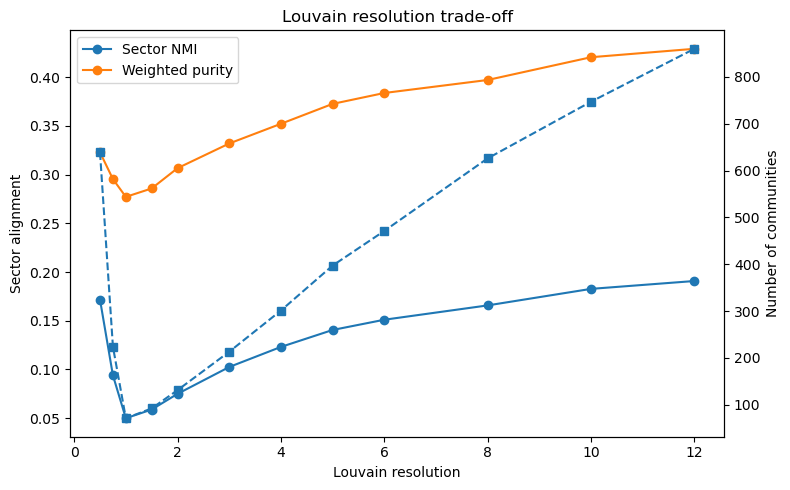

In [17]:
# Resolution trade-off figure
fig, ax1 = plt.subplots(figsize=(8, 5))

ax1.plot(
    resolution_sweep["resolution"],
    resolution_sweep["sector_nmi"],
    marker="o",
    label="Sector NMI"
)

ax1.plot(
    resolution_sweep["resolution"],
    resolution_sweep["weighted_purity"],
    marker="o",
    label="Weighted purity"
)

ax1.set_xlabel("Louvain resolution")
ax1.set_ylabel("Sector alignment")
ax1.legend(loc="upper left")

ax2 = ax1.twinx()
ax2.plot(
    resolution_sweep["resolution"],
    resolution_sweep["communities"],
    marker="s",
    linestyle="--",
    label="Number of communities"
)

ax2.set_ylabel("Number of communities")

plt.title("Louvain resolution trade-off")
plt.tight_layout()

fig_path = os.path.join(
    OUTPUT_DIR, "community_resolution_tradeoff.png"
)

plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

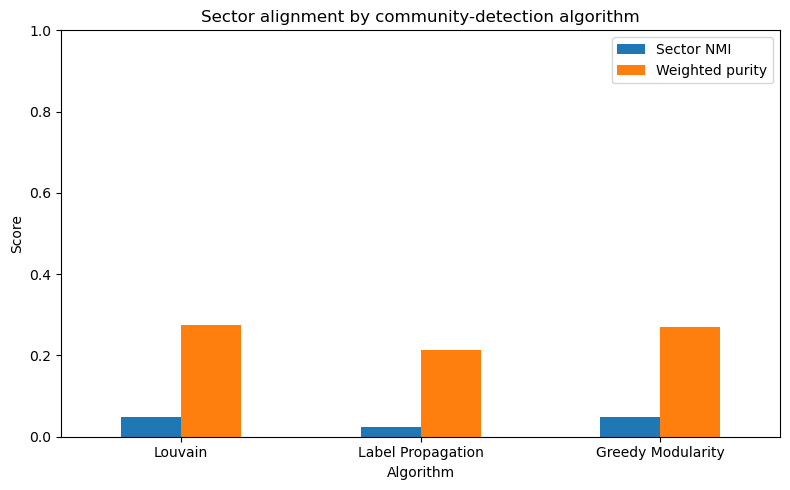

In [18]:
# Sector alignment by algorithm
plot_df = algorithm_results.set_index("Algorithm")[
    ["Sector NMI", "Weighted purity"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(8, 5)
)

ax.set_ylabel("Score")
ax.set_title("Sector alignment by community-detection algorithm")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()

fig_path = os.path.join(
    OUTPUT_DIR, "community_algorithm_alignment.png"
)

plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

## Qualitative inspection of the largest Louvain communities

This is useful for checking whether the largest topology-derived communities are sector-homogeneous or cross-sector.

In [19]:
def community_sector_summary(coms, node_to_sector, top_n=15):
    rows = []

    communities_sorted = sorted(
        enumerate(coms.communities),
        key=lambda x: len(x[1]),
        reverse=True
    )

    for cid, community in communities_sorted[:top_n]:
        labels = [node_to_sector[n] for n in community]
        counts = Counter(labels)
        dominant_sector, dominant_count = counts.most_common(1)[0]

        rows.append({
            "community": cid,
            "size": len(community),
            "dominant_sector": dominant_sector,
            "dominant_sector_share": dominant_count / len(community),
        })

    return pd.DataFrame(rows)

display(
    community_sector_summary(
        communities["Louvain"],
        node_to_sector
    )
)

,community,size,dominant_sector,dominant_sector_share
0,0,2228,Healthcare,0.307002
1,1,1213,Financial Services,0.216818
2,2,703,Healthcare,0.226174
3,3,496,Consumer Cyclical,0.215726
4,4,176,Financial Services,0.363636
5,5,147,Financial Services,0.170068
6,6,48,Financial Services,0.312500
7,7,7,Financial Services,0.857143
8,8,5,Financial Services,0.800000
9,9,3,Financial Services,1.000000


## Final reproducibility check

If these values differ from the report, check the graph construction, metadata version, known-sector filtering, CDlib version, random seed, Louvain parameters, and weighted-purity definition before changing any numbers.

In [20]:
print("=== FINAL COMMUNITY-DETECTION TABLE ===")
display(
    report_table.style.format({
        "Modularity": "{:.3f}",
        "Sector NMI": "{:.3f}",
        "Weighted purity": "{:.3f}",
    })
)

print("\n=== LOUVAIN RESOLUTION = 12 ===")
display(
    resolution_sweep[
        resolution_sweep["resolution"] == 12
    ]
)

print("\n=== OUTPUT FILES ===")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", os.path.join(OUTPUT_DIR, filename))

=== FINAL COMMUNITY-DETECTION TABLE ===


,Algorithm,Communities,Modularity,Sector NMI,Weighted purity
0,Louvain,70,0.212,0.049,0.274
1,Label Propagation,62,0.000,0.024,0.214
2,Greedy Modularity,79,0.198,0.048,0.270



=== LOUVAIN RESOLUTION = 12 ===


,resolution,communities,modularity,sector_nmi,weighted_purity
11,12.0,860,0.059256,0.190752,0.429189



=== OUTPUT FILES ===
- analysis_outputs\community_algorithm_alignment.png
- analysis_outputs\community_algorithm_partition_comparison.csv
- analysis_outputs\community_algorithm_variant_comparison.csv
- analysis_outputs\community_louvain_resolution_sweep.csv
- analysis_outputs\community_resolution_tradeoff.png
- analysis_outputs\community_sector_diagnostics.csv
